In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Подключаем три библиотеки: pandas — для работы с таблицами, seaborn — для построения тепловой карты, matplotlib — для отображения графика.

In [2]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Считываем CSV-файл с данными о пассажирах «Титаника» в таблицу df.

In [3]:
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()
y = df["Survived"].copy()

Выбор признаков и определение целевой переменной.

In [5]:
X.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0


Проверка пропущенных значений.

In [6]:
median_age = X["Age"].median()
X["Age"] = X["Age"].fillna(median_age)
print("Медиана возраста для заполнения пропусков:", median_age)

Медиана возраста для заполнения пропусков: 28.0


Находим медианный возраст (28.0) и заполняем им все пустые ячейки. Медиана лучше среднего, потому что не искажается редкими очень большими или маленькими значениями.

In [7]:
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
print(X.isnull().sum())
print(X.head())

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64
   Pclass   Age  Sex     Fare  SibSp  Parch
0       3  22.0    0   7.2500      1      0
1       1  38.0    1  71.2833      1      0
2       3  26.0    1   7.9250      0      0
3       1  35.0    1  53.1000      1      0
4       3  35.0    0   8.0500      0      0


Преобразование Sex в числовое. Корреляция считается только для чисел, поэтому заменяем текст: male → 0, female → 1.

In [8]:
data = X.copy()
data["Survived"] = y
print(data.columns)
print(data.dtypes)
print(data.isnull().sum())
print(data.head())

Index(['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived'], dtype='object')
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


Формирование таблицы для анализа. Объединяем признаки X и целевую переменную y в одну таблицу data, чтобы посчитать корреляцию между всеми столбцами сразу.

In [9]:
corr_matrix = data.corr()
corr_matrix = corr_matrix.round(2)
print(corr_matrix)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


Метод .corr() считает коэффициент Пирсона для каждой пары столбцов. .round(2) округляет до 2 знаков. Получаем таблицу, где на пересечении строки и столбца — сила связи между двумя признаками.

In [10]:
corr_with_survived = corr_matrix["Survived"].drop("Survived")
print(corr_with_survived)

max_corr = corr_with_survived.idxmax()
print("Наибольшая положительная корреляция:", max_corr, "=", corr_with_survived[max_corr])

min_corr = corr_with_survived.idxmin()
print("Наибольшая отрицательная корреляция:", min_corr, "=", corr_with_survived[min_corr])

Pclass   -0.34
Age      -0.06
Sex       0.54
Fare      0.26
SibSp    -0.04
Parch     0.08
Name: Survived, dtype: float64
Наибольшая положительная корреляция: Sex = 0.54
Наибольшая отрицательная корреляция: Pclass = -0.34


Далее смотрим столбец Survived:

Наибольшая положительная корреляция — Sex (~0.54): чем больше значение (т.е. чем больше женщин), тем выше выживаемость.

Наибольшая отрицательная корреляция — Pclass (~-0.34): чем выше номер класса (3-й — самый дешёвый), тем ниже шанс выжить.

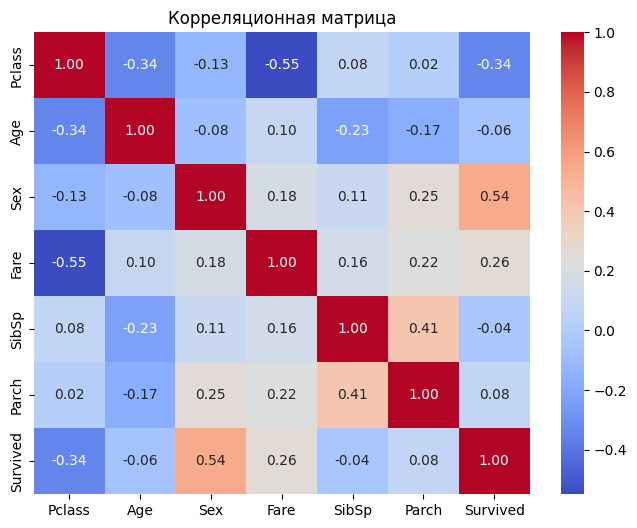

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Корреляционная матрица")
plt.show()

Описание:

plt.figure(figsize=(8, 6)) — задаём размер картинки 8×6 дюймов.

sns.heatmap(...) — строим тепловую карту.

annot=True — показывает числа внутри ячеек.

cmap="coolwarm" — сине-красная палитра (синий = отрицательная связь, красный = положительная).

fmt=".2f" — формат чисел с 2 знаками после запятой.

plt.title(...) — добавляем заголовок.

1. Какие признаки наиболее полезны для предсказания Survived?

Наиболее полезны Sex (пол), Pclass (класс каюты) и Fare (цена билета), так как у них самая сильная статистическая связь с выживаемостью.

2. Можно ли выбирать признаки для модели только на основании корреляции?
Нет, нельзя.

Во-первых, коэффициент Пирсона находит только линейные связи и не видит сложных нелинейных зависимостей.

Во-вторых, признаки могут сильно коррелировать друг с другом (например, Pclass и Fare), что создает дублирование информации и может ухудшить работу модели.